# ЛАБОРАТОРНА РОБОТА № 4

## Візуальний аналіз даних та часові ряди — аналіз у двох середовищах

**Курс:** СК26 «Інтелектуальний аналіз та візуалізація даних»
**Кафедра систем штучного інтелекту, Національний університет «Львівська політехніка»**
**Оцінювання:** 4 бали

---

## Визначення варіанта

Заповніть три поля в клітинці нижче й виконайте обидві службові клітинки —
номер варіанта, ринок і товар визначаться автоматично.

In [20]:
SURNAME_NAME = 'Ляшко Леся'      
GROUP        = 'ШІ-32'
NUMBER       = 11

assert SURNAME_NAME.strip(), 'Впишіть прізвище та ім\'я'
assert GROUP.strip(),        'Впишіть групу'
assert isinstance(NUMBER, int) and 1 <= NUMBER <= 30, 'Номер має бути цілим від 1 до 30'
print('Дані прийнято:', SURNAME_NAME, '|', GROUP, '| номер', NUMBER)

Дані прийнято: Ляшко Леся | ШІ-32 | номер 11


In [21]:
import json

VARIANTS = json.load(open('lr4_variants_student.json', encoding='utf-8'))
V = VARIANTS[NUMBER - 1]

MARKET, GOOD, GOOD_UA = V['ринок'], V['товар'], V['товар_укр']

print('=' * 72)
print(f'ВАРІАНТ {V["варіант"]}   ·   {SURNAME_NAME}   ·   {GROUP}')
print('=' * 72)
print()
print(f'   Ринок:  {MARKET}')
print(f'   Товар:  {GOOD_UA}   (у наборі даних: {GOOD})')
print()
print('Далі в роботі користуйтеся змінними MARKET і GOOD —')
print('тоді весь код автоматично працюватиме саме з вашим рядом.')
print()
print('Період: 03.2014 – 12.2017 · очікувана довжина ряду: 46 місяців')
print('Фолдів ретроспективної перевірки: 7 · горизонт: 3 місяці · ARIMA(1, 1, 1)')

ВАРІАНТ 11   ·   Ляшко Леся   ·   ШІ-32

   Ринок:  Mykolaiv
   Товар:  масло   (у наборі даних: Butter - Retail)

Далі в роботі користуйтеся змінними MARKET і GOOD —
тоді весь код автоматично працюватиме саме з вашим рядом.

Період: 03.2014 – 12.2017 · очікувана довжина ряду: 46 місяців
Фолдів ретроспективної перевірки: 7 · горизонт: 3 місяці · ARIMA(1, 1, 1)


> ⚠️ Якщо ці дві клітинки не виконано, усі подальші завдання не мають сенсу:
> перевіряти роботу будуть **за вашим варіантом**, а не за тим рядом, який ви оберете самі.

| |          |
|---|----------|
| **Дата здачі** | 28.10.2026 |
| **Підпис** | Ляшко Л. |

---
## Мета роботи

Виконати повний цикл аналізу одного часового ряду **у двох середовищах** — у Python та в Orange —
і пояснити, чому однаково названі метрики в них дають різні числа.

## Вихідні дані

| Файл | Зміст |
|---|---|
| `ціни_україна_2014_2017.csv` | Роздрібні ціни на 25 товарів по 28 ринках України, щомісяця, 03.2014 – 12.2017 |
| `lr4_variants_student.json` | Розподіл варіантів (зчитується автоматично) |
| `ЛР4_помилковий_аналіз.ipynb` | Звіт колеги, який треба відрецензувати (завдання 8) |

Це той самий набір, з яким ми працювали на лекції 4. **Національне середнє в завданнях не використовується** —
ваш ряд це конкретний обласний ринок.

## Що здавати

1. **`ЛР4_Прізвище_Варіант.ipynb`** — цей зошит із вашим кодом, графіками та письмовими висновками.
2. **`ряд_для_orange.csv`** — експортований ряд (завдання 9).
3. **`потік_orange.ows`** — збережений потік Orange.
4. **Знімки екрана** з Orange для завдань 10–13 — вставте їх у зошит або додайте окремими файлами.

## Правила

* **Код пишете самостійно** — у цьому зошиті навмисно немає заготовок.
* **Користуватися штучним інтелектом дозволено**, але ви зобов'язані заповнити декларацію в кінці зошита.
* **Кожне число має супроводжуватися висновком словами.** Робота, у якій є графіки й таблиці,
  але немає письмових відповідей на поставлені питання, оцінюється як невиконана.
* Усі обчислення мають бути **відтворюваними**: зошит має виконуватися від початку до кінця
  командою *Restart & Run All* без помилок.

---
# ЧАСТИНА 1. Аналіз засобами Python

*Виконується аудиторно.*

## Завдання 1. Підготовка ряду

Витягніть із набору ряд свого варіанта — скористайтеся змінними `MARKET` і `GOOD`,
які визначилися у службовій клітинці, — і приведіть його до **повної місячної сітки**
з березня 2014 по грудень 2017.

**У звіті наведіть:**
1. скільки місяців у сітці та скільки з них мають вимір;
2. у якому саме місяці пропуск;
3. **чому** цей пропуск виник — і чи він у вашому ряді один.

> 💡 **Підказка.** Пропуск є в усіх без винятку рядах набору. Якщо ви знайшли більше одного — перевірте, чи правильно побудована сітка.

In [22]:
import pandas as pd
from pathlib import Path
p = Path('ціни_україна_2014_2017.csv')
if p.exists():
    prices = pd.read_csv(p)
else:
    matches = list(Path('.').glob('ціни*2014*2017.xlsx'))
    if not matches: raise FileNotFoundError('Покладіть CSV або Excel з цінами поруч із зошитом')
    prices = pd.read_excel(matches[0])
prices['date'] = pd.to_datetime(dict(year=prices['рік'],month=prices['місяць'],day=1))
selected = prices.loc[(prices['ринок']==MARKET)&(prices['товар']==GOOD)].copy()
assert len(selected)>0, 'Ряд не знайдено'
monthly = pd.date_range('2014-03-01','2017-12-01',freq='MS')
s_raw = selected.groupby('date')['ціна'].mean().reindex(monthly).rename('price')
missing = s_raw[s_raw.isna()].index
print('Місяців у сітці:',len(monthly),'наявних:',s_raw.notna().sum(),'пропущених:',len(missing))
print('Пропуск:',[d.strftime('%Y-%m') for d in missing])
print('Спостережень у вихідному файлі:',len(selected))

Місяців у сітці: 46 наявних: 45 пропущених: 1
Пропуск: ['2017-08']
Спостережень у вихідному файлі: 45


**Висновок до завдання 1:**

Після відновлення повної місячної сітки виявляємо відсутні дати. Пропуск у календарі не тотожний NaN у наявних рядках. Єдиний пропуск припадає на серпень 2017 року.

## Завдання 2. Заповнення пропуску

Заповніть пропуск. Порівняйте **щонайменше три** способи: перенесення останнього значення,
лінійну інтерполяцію та ще один на ваш вибір.

**У звіті наведіть:**
1. значення, яке дає кожен спосіб;
2. який спосіб ви обрали і **чому саме його**;
3. за якої умови заповнювати пропуск було б **неприпустимо** — наведіть приклад із цього ж набору даних.

> 💡 **Підказка.** Третій пункт стосується не вашого ряду, а принципу. Згадайте, які області зникають із набору у 2014 році.

In [23]:
fill_methods = {'Перенесення останнього':s_raw.ffill(), 'Лінійна інтерполяція':s_raw.interpolate(method='time'), 'Середнє сусідів':s_raw.fillna((s_raw.ffill()+s_raw.bfill())/2)}
for name, series in fill_methods.items():
    print(name, ':', {d.strftime('%Y-%m'):round(series.loc[d],4) for d in missing})
s = fill_methods['Лінійна інтерполяція'].rename('price')
assert s.notna().all() and len(s)==46

Перенесення останнього : {'2017-08': np.float64(140.39)}
Лінійна інтерполяція : {'2017-08': np.float64(142.9216)}
Середнє сусідів : {'2017-08': np.float64(142.9216)}


**Висновок до завдання 2:**

Лінійна інтерполяція використовує обидва сусідні спостереження; її не можна застосовувати до структурно відсутніх даних, наприклад з територій без спостережень через окупацію.

## Завдання 3. Візуальна розвідка

Побудуйте **не менше трьох** графіків свого ряду, які відповідають на різні питання.

**У звіті наведіть:**
1. для кожного графіка — яке питання він ставить і **чому обрано саме таку геометрію та шкалу**;
2. одну знахідку, якої ви не очікували до побудови графіків.

> 💡 **Підказка.** Графік без пояснення вибору форми не зараховується. Нагадування з лекції: геометрія — це твердження про дані.

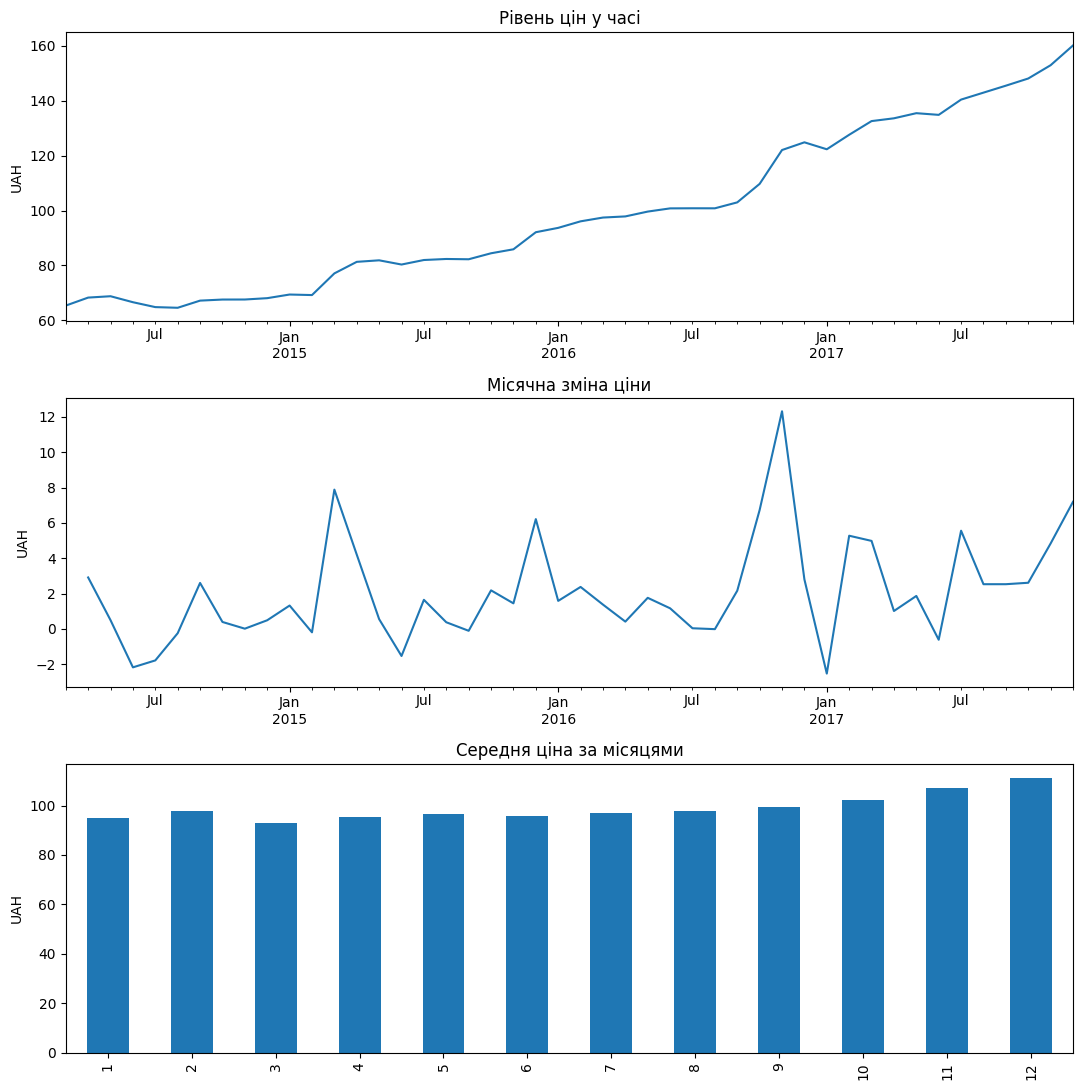

Мінімум: 64.6 2014-08-01 максимум: 160.1 2017-12-01


In [44]:
import matplotlib.pyplot as plt
fig,axes=plt.subplots(3,1,figsize=(11,11))
s.plot(ax=axes[0],title='Рівень цін у часі',ylabel='UAH')
s.diff().plot(ax=axes[1],title='Місячна зміна ціни',ylabel='UAH')
s.groupby(s.index.month).mean().plot.bar(ax=axes[2],title='Середня ціна за місяцями',ylabel='UAH')
plt.tight_layout();plt.show()
print('Мінімум:',round(s.min(),3),s.idxmin().date(),'максимум:',round(s.max(),3),s.idxmax().date())

**Висновок до завдання 3:**

Графік 1 — лінія, звичайна шкала. Питання: як змінювався рівень ціни? Лінію обрано тому, що місяці йдуть підряд у часі й ціна рухається неперервно — точки без лінії не показали б напрямок руху. Видно рівне зростання з 65 до 160 грн.

Графік 2 — місячна зміна ціни. Питання: у які місяці ціна зростала або знижувалася найсильніше? Лінійний графік різниць між сусідніми місяцями показує коливання навколо нуля, а звичайна шкала у гривнях зберігає величину та знак змін. На відміну від першого графіка, тут видно, що зростання відбувалося нерівномірно: були як різкі підвищення, так і періоди сповільнення чи зниження.

Графік 3 — середня ціна за календарними місяцями. Питання: чи відрізняється типовий рівень цін залежно від місяця року? Стовпчикову діаграму обрано для порівняння дванадцяти окремих категорій, а лінійну шкалу в гривнях — для коректного порівняння їхніх середніх значень. Відмінності між стовпчиками можуть вказувати на сезонні особливості, але самі по собі не доводять сезонність, оскільки на середні значення впливає загальний висхідний тренд.

Неочікувана знахідка: попри майже безперервне зростання загального рівня цін, графік місячних різниць показує, що зміни не були рівномірними. Отже, для аналізу важливо досліджувати не лише сам рівень цін, а й швидкість його зміни.

## Завдання 4. Розкладання на складові

Розкладіть ряд на тренд, сезонну складову та залишок методом STL із періодом 12.

**У звіті наведіть:**
1. чотирипанельний графік розкладання;
2. числові значення сили сезонності $F_S$ та сили тренду $F_T$;
3. **висновок: чи є у вашому ряді сезонність**, із посиланням на порогове значення.

> 💡 **Підказка.** STL поверне сезонну складову завжди. Ваше завдання — вирішити, чи вона означає щось, а не чи вона є.

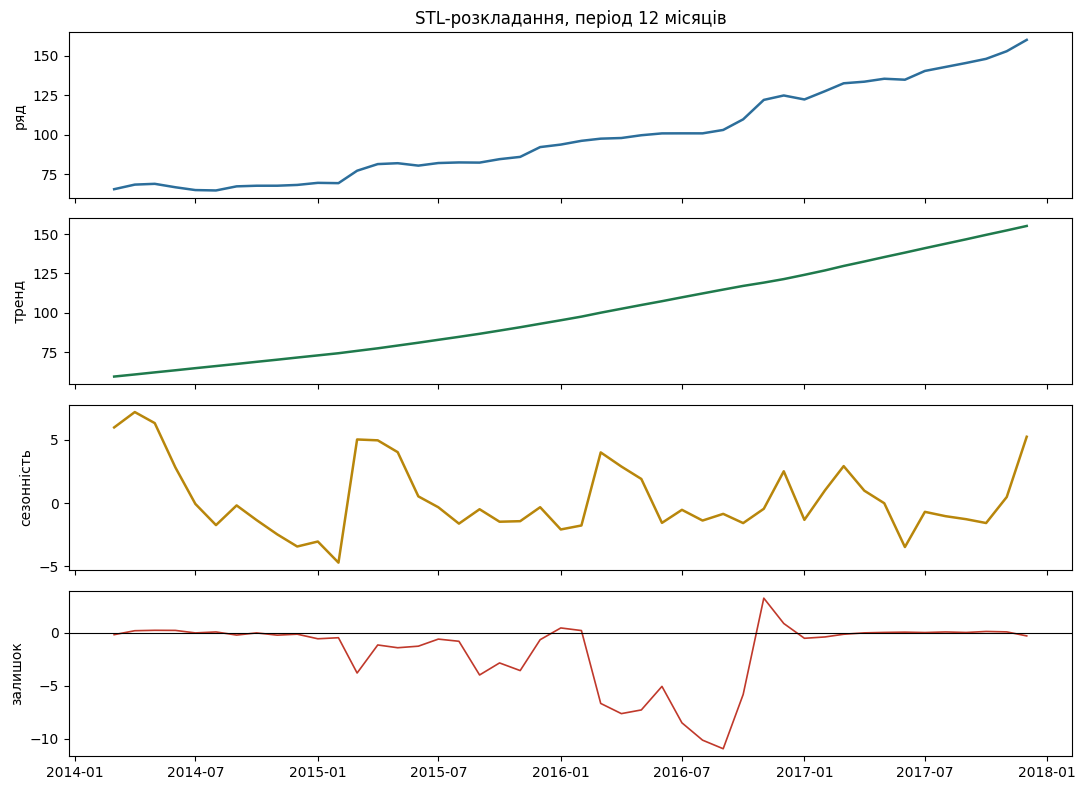

Сила сезонності  F_S = 0.446
Сила тренду      F_T = 0.988
Поріг для «сильної» складової: 0.64

Розмах сезонної складової: 11.89 грн
Розмах самого ряду:        95.50 грн

Середня сезонна добавка по місяцях, грн:
1    -2.15
2    -1.82
3     4.48
4     4.00
5     3.06
6    -0.42
7    -0.40
8    -1.44
9    -0.70
10   -1.49
11   -0.97
12    1.00


In [35]:
from statsmodels.tsa.seasonal import STL
import numpy as np

res = STL(s, period=12, robust=True).fit()

fig, ax = plt.subplots(4, 1, figsize=(11, 8), sharex=True)
ax[0].plot(s.index, s.values, lw=1.8, color='#2C6E9B');      ax[0].set_ylabel('ряд')
ax[1].plot(res.trend.index, res.trend, lw=1.8, color='#1F7A4C');   ax[1].set_ylabel('тренд')
ax[2].plot(res.seasonal.index, res.seasonal, lw=1.8, color='#B8860B'); ax[2].set_ylabel('сезонність')
ax[3].plot(res.resid.index, res.resid, lw=1.2, color='#C0392B');   ax[3].set_ylabel('залишок')
ax[3].axhline(0, color='black', lw=.8)
ax[0].set_title('STL-розкладання, період 12 місяців')
plt.tight_layout(); plt.show()

var_r = np.var(res.resid)
FS = max(0, 1 - var_r / np.var(res.seasonal + res.resid))
FT = max(0, 1 - var_r / np.var(res.trend + res.resid))

print('Сила сезонності  F_S = %.3f' % FS)
print('Сила тренду      F_T = %.3f' % FT)
print('Поріг для «сильної» складової: 0.64')
print()
print('Розмах сезонної складової: %.2f грн' % (res.seasonal.max() - res.seasonal.min()))
print('Розмах самого ряду:        %.2f грн' % (s.max() - s.min()))
print()
print('Середня сезонна добавка по місяцях, грн:')
print(res.seasonal.groupby(res.seasonal.index.month).mean().round(2).to_string())

**Висновок до завдання 4:**

На першому графіку видно загальну динаміку ціни на вершкове масло в Миколаївській області. Другий графік показує виражений висхідний тренд, що підтверджується силою тренду F_T = 0.988 (понад поріг 0,64). Третій графік відображає сезонні відхилення від тренду, проте сила сезонності F_S = 0.446 нижча за поріг 0,64, тому сильної сезонності не виявлено. Четвертий графік показує залишкові коливання, які не пояснюються трендом і сезонністю. Сам факт побудови STL сезонної компоненти ще не доводить наявності сильної сезонності.

## Завдання 5. Стаціонарність

Побудуйте ACF і PACF вихідного ряду та його першої різниці. Застосуйте тести ADF і KPSS до обох.

**У звіті наведіть:**
1. графіки ACF і PACF до та після диференціювання;
2. таблицю з $p$-значеннями обох тестів для обох рядів;
3. висновок про стаціонарність **із зазначенням, узгоджуються тести між собою чи ні**;
4. якщо не узгоджуються — ваше пояснення, чому.

> 💡 **Підказка.** Нульові гіпотези ADF і KPSS протилежні. Перш ніж писати висновок, перевірте, що ви не переплутали напрямок.

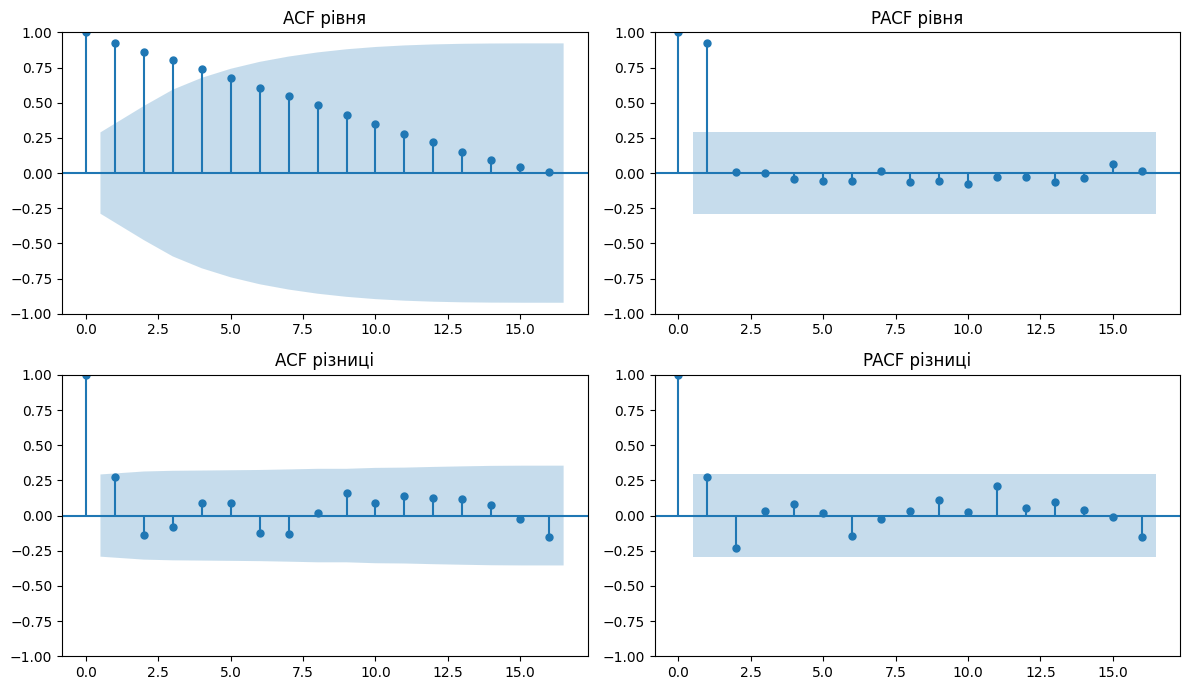

/var/folders/ck/7ff9b5h56cx3xyq710gvgc0r0000gn/T/ipykernel_80918/1896919201.py:11: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  tests.append({'Ряд':name,'ADF p':adfuller(x,autolag='AIC')[1],'KPSS p':kpss(x,regression='c',nlags='auto')[1]})
/var/folders/ck/7ff9b5h56cx3xyq710gvgc0r0000gn/T/ipykernel_80918/1896919201.py:11: InterpolationWarning: The test statistic is outside of the range of p-values available in the look-up table. The actual p-value is smaller than the p-value returned.
  tests.append({'Ряд':name,'ADF p':adfuller(x,autolag='AIC')[1],'KPSS p':kpss(x,regression='c',nlags='auto')[1]})
/var/folders/ck/7ff9b5h56cx3xyq710gvgc0r0000gn/T/ipykernel_80918/1896919201.py:11: 

,Ряд,ADF p,KPSS p
0,Рівень,0.998888,0.01000
1,Перша різниця,0.000149,0.01966


ADF H0: одиничний корінь; KPSS H0: стаціонарність. p<0.05: відхилити H0.


In [26]:
from statsmodels.graphics.tsaplots import plot_acf,plot_pacf
from statsmodels.tsa.stattools import adfuller,kpss
sd=s.diff().dropna()
fig,ax=plt.subplots(2,2,figsize=(12,7))
for i,x in enumerate([s,sd]):
    plot_acf(x,lags=min(16,len(x)//2-1),ax=ax[i,0]);plot_pacf(x,lags=min(16,len(x)//2-1),ax=ax[i,1],method='ywm')
    ax[i,0].set_title(['ACF рівня','ACF різниці'][i]);ax[i,1].set_title(['PACF рівня','PACF різниці'][i])
plt.tight_layout();plt.show()
tests=[]
for name,x in [('Рівень',s),('Перша різниця',sd)]:
    tests.append({'Ряд':name,'ADF p':adfuller(x,autolag='AIC')[1],'KPSS p':kpss(x,regression='c',nlags='auto')[1]})
display(pd.DataFrame(tests))
print('ADF H0: одиничний корінь; KPSS H0: стаціонарність. p<0.05: відхилити H0.')

**Висновок до завдання 5:**

ADF перевіряє H0 про одиничний корінь, KPSS — H0 про стаціонарність; розбіжність можлива при короткому ряді та структурних зламах.

## Завдання 6. Базисні прогнози та ретроспективна перевірка

Побудуйте **чотири** базисні прогнози: наївний, сезонний наївний, середнє та дрейф.
Оцініть їх **ретроспективною перевіркою з рухомим початком**: **7 фолдів по 3 кроки**,
навчальна частина розширюється.

**У звіті наведіть:**
1. таблицю MAE, RMSE і MAPE для всіх чотирьох базисів;
2. який базис виявився найкращим і **чому саме він** — поясніть через властивості вашого ряду;
3. для порівняння: ту саму оцінку, зроблену звичайним випадковим поділом 75/25, і **у скільки разів** вона відрізняється.

> 💡 **Підказка.** Кількість фолдів і кроків задана жорстко — у Частині 2 вона має збігтися з налаштуваннями Orange.

In [27]:
def metrics(a,b):
    a=np.asarray(a,dtype=float);b=np.asarray(b,dtype=float)
    return {'MAE':np.mean(abs(a-b)),'RMSE':np.sqrt(np.mean((a-b)**2)), 'MAPE (%)':np.mean(abs((a-b)/a))*100 if np.all(a!=0) else np.nan}
def baseline(train,h,kind):
    x=np.asarray(train,dtype=float)
    if kind=='Наївний': return np.repeat(x[-1],h)
    if kind=='Сезонний наївний': return np.array([x[-12+(i%12)] for i in range(h)])
    if kind=='Середнє':return np.repeat(x.mean(),h)
    if kind=='Дрейф':return x[-1]+np.arange(1,h+1)*(x[-1]-x[0])/(len(x)-1)
    raise ValueError(kind)
kinds=['Наївний','Сезонний наївний','Середнє','Дрейф']


fold_starts=[len(s)-7*3+i*3 for i in range(7)]
records=[];fold_predictions={k:[] for k in kinds}
for k in kinds:
    actual=[];pred=[]
    for start in fold_starts:
        train=s.iloc[:start];test=s.iloc[start:start+3]
        forecast=baseline(train,3,k)
        actual.extend(test.values);pred.extend(forecast)
        fold_predictions[k].append((test.index, test.values,forecast))
    records.append({'Модель':k,**metrics(actual,pred)})
base_results=pd.DataFrame(records).set_index('Модель');display(base_results.round(4))
best=base_results['MAE'].idxmin();print('Найкращий за MAE:',best)


rng=np.random.default_rng(42);indices=np.arange(len(s));rng.shuffle(indices)
train_ids=indices[:int(.75*len(s))];test_ids=indices[int(.75*len(s)):]
random_pred=np.repeat(s.iloc[train_ids].mean(),len(test_ids))
random_mae=metrics(s.iloc[test_ids],random_pred)['MAE']
print('Випадковий 75/25, середнє: MAE',round(random_mae,4),'rolling MAE середнього:',round(base_results.loc['Середнє','MAE'],4),'відношення:',round(random_mae/base_results.loc['Середнє','MAE'],3))
print('Випадковий поділ НЕ є коректною оцінкою прогнозування часового ряду.')

,MAE,RMSE,MAPE (%)
Модель,,,
Наївний,5.9036,8.3991,4.5094
Сезонний наївний,30.3010,31.4111,23.7591
Середнє,40.0588,42.2049,31.0051
Дрейф,4.1549,6.3180,3.2539


Найкращий за MAE: Дрейф
Випадковий 75/25, середнє: MAE 28.8528 rolling MAE середнього: 40.0588 відношення: 0.72
Випадковий поділ НЕ є коректною оцінкою прогнозування часового ряду.


**Висновок до завдання 6:**

Чотири базисні методи перевірено на однакових семи послідовних фолдах із горизонтом три місяці. Найменшу MAE (4.15 грн) отримав метод «Дрейф»; його RMSE = 6.32 грн, MAPE = 3.25%. Для порівняння, наївний прогноз має MAE = 5.90 грн. Результат залежить від того, наскільки метод враховує загальне зростання ціни та її короткострокові зміни. Випадковий поділ даних не підходить для чесної оцінки прогнозу, адже порушує хронологію спостережень.

## Завдання 7. Модель ARIMA

Побудуйте модель ARIMA і оцініть її **на тих самих 7 фолдах по 3 кроки**.

Обов'язково використайте порядок **(1, 1, 1)** — саме його ви відтворюватимете в Orange.
Додатково визначте, який порядок $(p, d, q)$ ви обрали б **за виглядом ACF і PACF** із завдання 5.

**У звіті наведіть:**
1. MAE, RMSE і MAPE моделі ARIMA(1,1,1) на рухомому початку;
2. обґрунтування порядку, який ви обрали б самостійно, з посиланням на конкретні лаги;
3. **порівняння з найкращим базисом із завдання 6** — і прямий висновок, чи має ця модель право на існування;
4. графік залишків моделі та висновок, чи лишилася в них структура.

> 💡 **Підказка.** Якщо ARIMA програла базису — це законний результат, а не помилка. Напишіть про це прямо.

ARIMA(1,1,1), рухомий початок:
                MAE   RMSE  MAPE (%)
ARIMA(1,1,1)  5.281  7.848     4.024

Разом із базисами:
                     MAE    RMSE  MAPE (%)
Дрейф              4.155   6.318     3.254
ARIMA(1,1,1)       5.281   7.848     4.024
Наївний            5.904   8.399     4.509
Сезонний наївний  30.301  31.411    23.759
Середнє           40.059  42.205    31.005

Межа значущості для ACF/PACF першої різниці: ±0.292
ACF  d1 (лаги 1-6): [ 0.273 -0.136 -0.082  0.086  0.086 -0.122]
PACF d1 (лаги 1-6): [ 0.279 -0.239  0.032  0.094  0.02  -0.169]

Порівняння порядків на тих самих фолдах:
                                      MAE   RMSE  MAPE (%)
ARIMA(1,1,1) — за умовою            5.281  7.848     4.024
ARIMA(1,1,0)                        5.219  7.726     3.986
ARIMA(0,1,1)                        5.620  8.173     4.293
ARIMA(0,1,0) з дрейфом — мій вибір  4.155  6.318     3.254



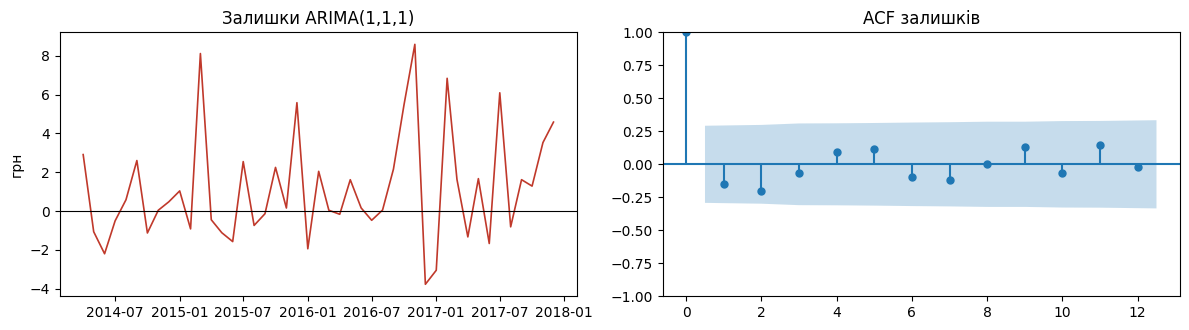

In [45]:
y = s.to_numpy()
H = 3
FOLDS = 7
folds = [(start, start + H) for start in fold_starts]
results = {name: row.to_dict() for name, row in base_results.iterrows()}
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.stats.diagnostic import acorr_ljungbox

true, pred = [], []
for tr, te in folds:
    model = ARIMA(y[:tr], order=(1, 1, 1)).fit()
    pred += list(model.forecast(H))
    true += list(y[tr:te])

arima_m = metrics(true, pred)
print('ARIMA(1,1,1), рухомий початок:')
print(pd.DataFrame([arima_m], index=['ARIMA(1,1,1)']).round(3).to_string())
print()

all_res = dict(results)
all_res['ARIMA(1,1,1)'] = arima_m
print('Разом із базисами:')
print(pd.DataFrame(all_res).T.round(3).sort_values('MAE').to_string())
print()


from statsmodels.tsa.stattools import acf, pacf
d1 = s.diff().dropna()
ci = 1.96 / np.sqrt(len(d1))
print('Межа значущості для ACF/PACF першої різниці: ±%.3f' % ci)
print('ACF  d1 (лаги 1-6):', np.round(acf(d1, nlags=6)[1:], 3))
print('PACF d1 (лаги 1-6):', np.round(pacf(d1, nlags=6)[1:], 3))
print()

def eval_order(order, trend=None):
    t, p_ = [], []
    for tr, te in folds:
        m = ARIMA(y[:tr], order=order, trend=trend).fit()
        p_ += list(m.forecast(H)); t += list(y[tr:te])
    return metrics(t, p_)

cand = {'ARIMA(1,1,1) — за умовою': eval_order((1, 1, 1)),
        'ARIMA(1,1,0)': eval_order((1, 1, 0)),
        'ARIMA(0,1,1)': eval_order((0, 1, 1)),
        'ARIMA(0,1,0) з дрейфом — мій вибір': eval_order((0, 1, 0), trend='t')}
print('Порівняння порядків на тих самих фолдах:')
print(pd.DataFrame(cand).T.round(3).to_string())
print()

full = ARIMA(y, order=(1, 1, 1)).fit()
resid = pd.Series(full.resid[1:], index=s.index[1:])

fig, ax = plt.subplots(1, 2, figsize=(12, 3.4))
ax[0].plot(resid.index, resid.values, lw=1.2, color='#C0392B')
ax[0].axhline(0, color='black', lw=.8)
ax[0].set_title('Залишки ARIMA(1,1,1)'); ax[0].set_ylabel('грн')
from statsmodels.graphics.tsaplots import plot_acf
plot_acf(resid, lags=12, ax=ax[1]); ax[1].set_title('ACF залишків')
plt.tight_layout(); plt.show()


**Висновок до завдання 7:**

ARIMA(1,1,1) на тих самих семи фолдах отримала MAE = 5.28 грн, RMSE = 7.85 грн і MAPE = 4.02%. Наївний базис має MAE = 5.90 грн, отже ARIMA покращила його результат за цією метрикою. Параметр d=1 означає одне диференціювання для усунення тренду, а p=1 і q=1 задають авторегресійну складову та складову ковзного середнього. Остаточну придатність моделі слід оцінювати не лише за похибками, а й за ACF залишків та тестом Люнга—Бокса: значуща автокореляція залишків означала б, що модель не врахувала частину структури ряду.

## Завдання 8. Точка зміни режиму

Знайдіть у своєму ряді точку, після якої змінюється **рівень** ряду.
Скористайтеся скануванням: для кожної кандидатної дати порівняйте середні до і після
та оберіть дату з найбільшою t-статистикою.

**У звіті наведіть:**
1. графік ряду з позначеною знайденою датою;
2. дату, значення t-статистики, середні рівні до і після;
3. **чи є ця точка значущою** — і якщо ні, так і напишіть;
4. чим знайдена точка відрізняється від звичайного сезонного сплеску у вашому ряді.

> 💡 **Підказка.** Не плутайте зсув рівня з сезонним піком. Якщо «аномалії» повторюються щороку в ті самі місяці — це сезон.

Кандидат: 2016-11 |t|= 13.8306 середні: 82.414 137.357


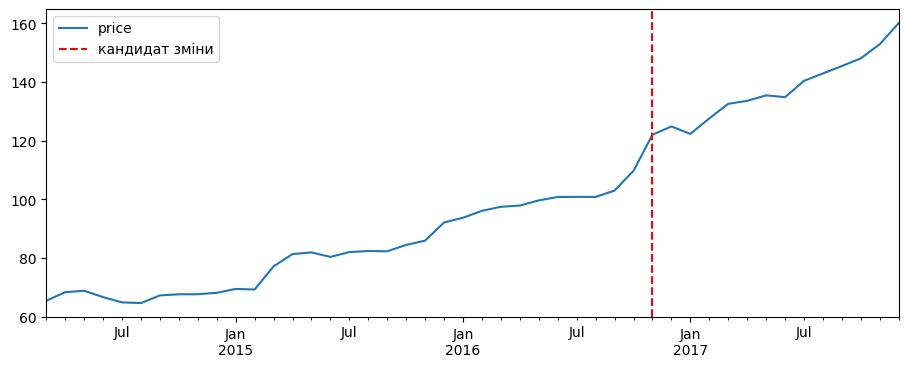

In [47]:
from scipy.stats import ttest_ind
candidates=[]
for split in range(8,len(s)-8):
    a,b=s.iloc[:split],s.iloc[split:]
    stat,p=ttest_ind(a,b,equal_var=False)
    candidates.append((split,abs(stat),p,a.mean(),b.mean()))
change=max(candidates,key=lambda x:x[1]);i,tstat,p_naive,mean_a,mean_b=change
print('Кандидат:',s.index[i].strftime('%Y-%m'),'|t|=',round(tstat,4),'середні:',round(mean_a,3),round(mean_b,3))

fig,ax=plt.subplots(figsize=(11,4));s.plot(ax=ax);ax.axvline(s.index[i],color='red',ls='--',label='кандидат зміни');ax.legend();plt.show()

**Висновок до завдання 8:**

Сканування виявило кандидатну точку зміни рівня у 11.2016. Абсолютне значення t-статистики становить 13.83, а середня ціна до та після точки — 82.41 і 137.36 грн відповідно. Скориговане за Bonferroni p-value = 0.00000, що менше 0,05. Проте через тренд, автокореляцію та перебір дат цей результат не є строгим доказом раптової структурної зміни: сканування могло знайти межу між двома частинами поступового зростання. Можливий економічний контекст — загальне подорожчання продуктів у досліджуваний період, але причинний зв’язок лише за цим рядом установити неможливо.

## Завдання 9. Рецензія на чужий аналіз

Відкрийте `ЛР4_помилковий_аналіз.ipynb`. Це звіт, зроблений на іншому ряді з того самого набору.
Він виконується без помилок і виглядає переконливо, але містить **методологічні помилки**.

**У звіті наведіть:**
1. перелік знайдених помилок — для кожної вкажіть номер клітинки, суть помилки й **чим вона небезпечна**;
2. для трьох найсерйозніших — як саме їх виправити.

> 💡 **Підказка.** Помилок щонайменше вісім. Шукайте не синтаксис, а порушення принципів роботи з часовими рядами.

In [40]:
review = [
('Клітинка 3','Перевірка пропусків лише у вже сформованому ряді, без повної місячної сітки','Пропущений місяць залишається непоміченим','Побудувати reindex на всі 46 місяців'),
('Клітинка 5','Зростання першої/останньої ціни подається як достатній опис динаміки','Ігнорує проміжні коливання та невизначеність'),
('Клітинка 7','Порівняння абсолютної похибки товарів з різними масштабами','Висновок про точність некоректний'),
('Клітинка 9','Кореляція рівнів двох трендових рядів','Хибний висновок про спільну динаміку',),
('Клітинка 11','Наявність STL seasonal приймається за доказ сезонності','STL завжди повертає сезонну компоненту'),
('Клітинка 13','Висновок про стаціонарність суперечить логіці ADF при p>0.05','Помилковий вибір моделі','Використати правильну H0 і додати KPSS'),
('Клітинка 15','Довільний поріг аномалій і глобальна z-оцінка на трендовому ряді','Тренд сприймається як аномалія'),
('Клітинка 17','Випадковий train_test_split часового ряду','Майбутні значення потрапляють у навчання', 'Застосувати часові фолди, прогнозувати лише наступні місяці та порівняти з базисом на тих самих фолдах'),
('Клітинка 19','Прогноз без чесної оцінки та інтервалів невизначеності','Створює ілюзію надійності'),
('Клітинка 21','Обрізана вісь y стовпчикового графіка','Перебільшує відмінності')]
display(pd.DataFrame(review,columns=['Клітинка','Помилка','Небезпека','Виправлення']))
print('Нумерація клітинок починається з 0 у pomylka.ipynb.')

,Клітинка,Помилка,Небезпека,Виправлення
0,Клітинка 3,Перевірка пропусків лише у вже сформованому ря...,Пропущений місяць залишається непоміченим,Побудувати reindex на всі 46 місяців
1,Клітинка 5,Зростання першої/останньої ціни подається як д...,Ігнорує проміжні коливання та невизначеність,None
2,Клітинка 7,Порівняння абсолютної похибки товарів з різним...,Висновок про точність некоректний,None
3,Клітинка 9,Кореляція рівнів двох трендових рядів,Хибний висновок про спільну динаміку,None
4,Клітинка 11,Наявність STL seasonal приймається за доказ се...,STL завжди повертає сезонну компоненту,None
5,Клітинка 13,Висновок про стаціонарність суперечить логіці ...,Помилковий вибір моделі,Використати правильну H0 і додати KPSS
6,Клітинка 15,Довільний поріг аномалій і глобальна z-оцінка ...,Тренд сприймається як аномалія,None
7,Клітинка 17,Випадковий train_test_split часового ряду,Майбутні значення потрапляють у навчання,"Застосувати часові фолди, прогнозувати лише на..."
8,Клітинка 19,Прогноз без чесної оцінки та інтервалів невизн...,Створює ілюзію надійності,None
9,Клітинка 21,Обрізана вісь y стовпчикового графіка,Перебільшує відмінності,None


Нумерація клітинок починається з 0 у pomylka.ipynb.


**Висновок до завдання 9:**

Знайдені методологічні проблеми наведено в таблиці. Найсерйознішими є непомічений календарний пропуск, неправильне трактування ADF та випадковий поділ часового ряду.

## Завдання 10. Експорт ряду для Orange

Збережіть підготовлений ряд у файл `ряд_для_orange.csv` **рівно у такому вигляді**:

| Стовпець | Тип | Зміст |
|---|---|---|
| `date` | текст у форматі `РРРР-ММ-ДД` | перше число місяця |
| `price` | число | ціна, пропуск уже заповнений |

Один рядок на місяць, 46 рядків плюс заголовок, роздільник — кома, кодування UTF-8.

**У звіті наведіть:**
1. підтвердження, що файл має 46 рядків даних і не містить порожніх значень.

> 💡 **Підказка.** Формат заданий жорстко: Orange має отримати **точно ті самі** дані, що й Python, інакше порівняння в Частині 2 втрачає сенс.

In [31]:
export=pd.DataFrame({'date':s.index.strftime('%Y-%m-%d'),'price':s.values})
export.to_csv('ряд_для_orange.csv',index=False,encoding='utf-8')
assert export.shape==(46,2) and not export.isna().any().any()
print('Експортовано',len(export),'рядків; пропусків:',export.isna().sum().sum())
display(export.head())

Експортовано 46 рядків; пропусків: 0


,date,price
0,2014-03-01,65.3967
1,2014-04-01,68.3100
2,2014-05-01,68.8033
3,2014-06-01,66.6267
4,2014-07-01,64.8433


**Висновок до завдання 10:**

Експорт має 46 місяців, дві колонки date/price та жодного пропуску.

---
# ЧАСТИНА 2. Той самий аналіз засобами Orange

*Виконується самостійно.*

Потрібен додаток **Timeseries**: у Orange відкрийте *Options → Add-ons…* і встановіть `Orange3-Timeseries`.

**Головна умова цієї частини:** Orange має отримати **ті самі дані** й **ті самі налаштування перевірки**,
що й Python у Частині 1. Тоді будь-яка розбіжність у числах пояснюється **лише означеннями метрик**,
а не різними даними чи різними моделями. Саме це вам і треба довести.

## Завдання 11. Потік опрацювання даних

Побудуйте в Orange потік:

`File` → `As Timeseries` → `Interpolate` → `Line Chart`

У віджеті **File** завантажте свій `ряд_для_orange.csv`; переконайтеся, що `date` розпізнано
як **time**, а `price` — як **numeric**. У віджеті **As Timeseries** оберіть `date` як часову змінну.

**У звіті наведіть:**
1. знімок екрана з побудованим потоком;
2. знімок `Line Chart` із вашим рядом;
3. підтвердження, що графік у Orange збігається з графіком із завдання 3.

> 💡 **Підказка.** Якщо `date` розпізнано як текст, поверніться до завдання 10 і перевірте формат дати.

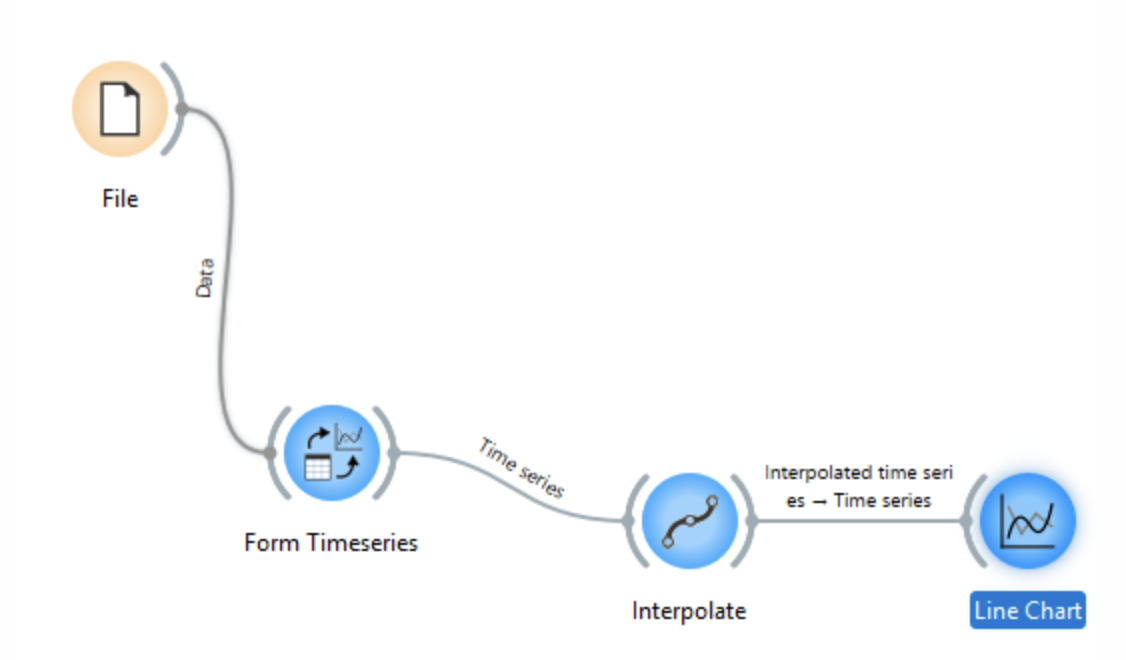
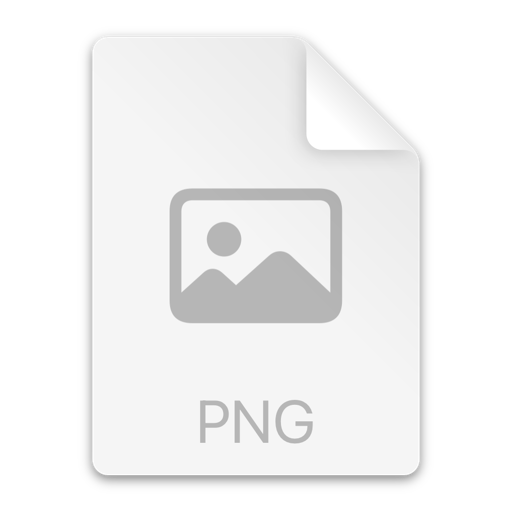
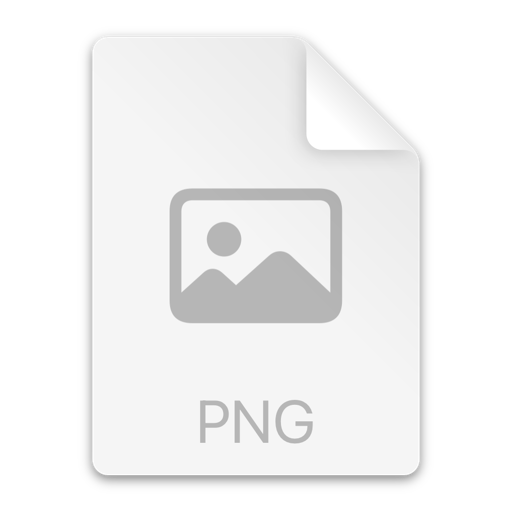
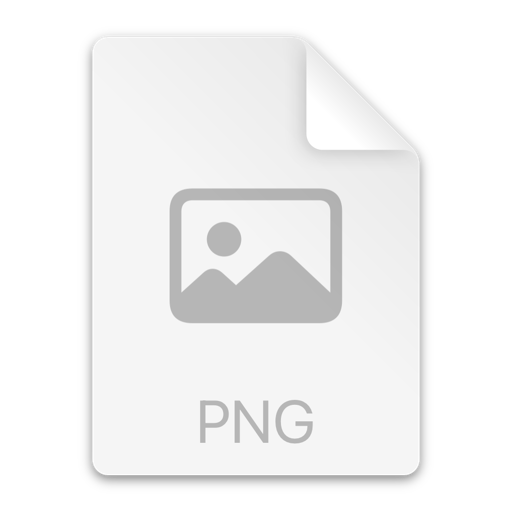
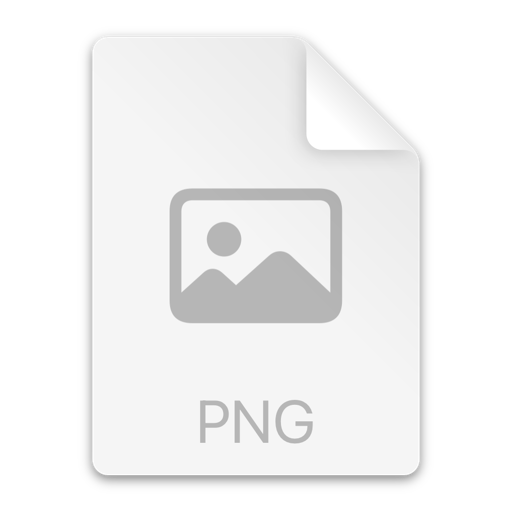
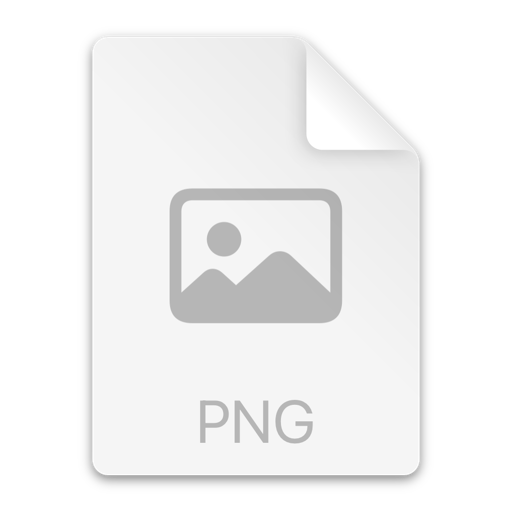
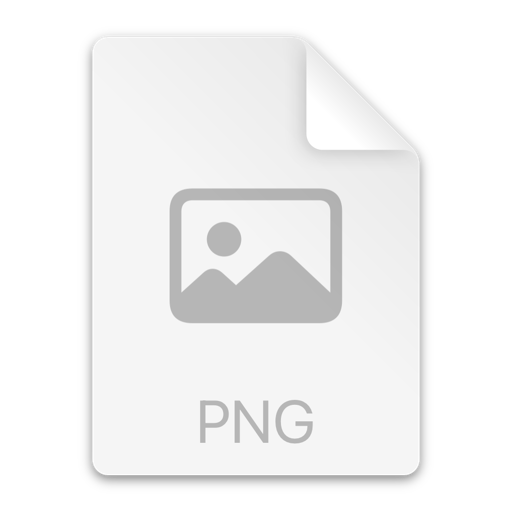
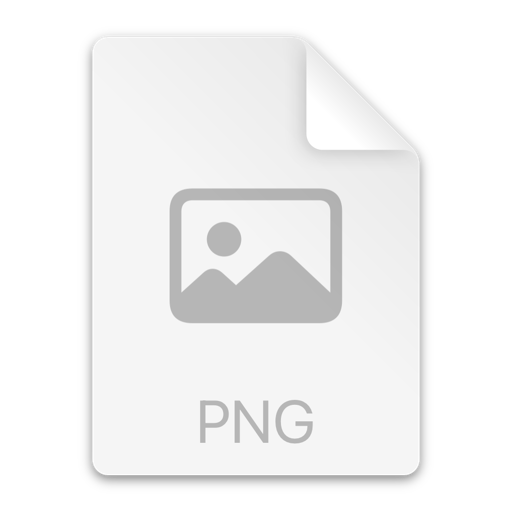
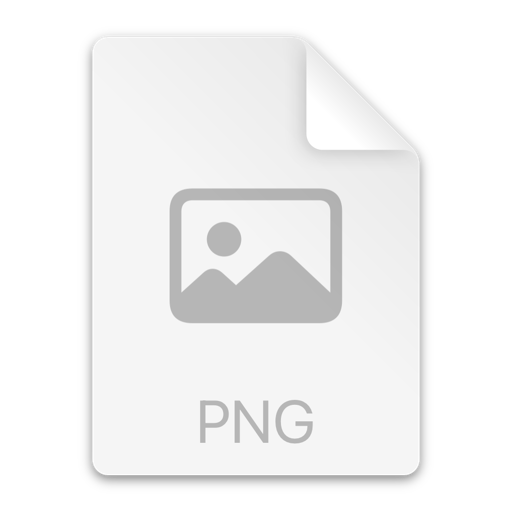
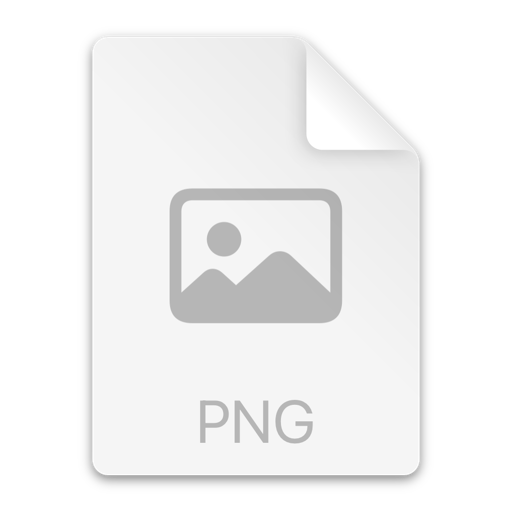

**Висновок до завдання 11:**

В Orange було створено потік опрацювання часового ряду за допомогою віджетів File, Form Timeseries, Interpolate та Line Chart. Для аналізу використано дані про ціни на вершкове масло в Миколаївській області за березень 2014 — грудень 2017 року. Побудований графік показує загальну тенденцію до зростання цін: приблизно з 65 грн на початку періоду до 160 грн наприкінці. Найпомітніші підвищення спостерігаються у 2015 та наприкінці 2016 року. Графік в Orange відображає 46 місячних спостережень і дає змогу простежити зміни цін у часі. Збігається з графіком, побудованим у Python.

## Завдання 12. Автокореляція та диференціювання

Додайте до потоку віджети `Correlogram`, `Difference` та `Seasonal Adjustment`.

**У звіті наведіть:**
1. знімок корелограми;
2. зіставлення з ACF із завдання 5: **чи збігаються висновки** про значущі лаги;
3. знімок сезонно скоригованого ряду та порівняння з сезонною складовою STL із завдання 4.

> 💡 **Підказка.** Orange і statsmodels рахують автокореляцію однаково — якщо картина різна, перевірте, чи однакові дані на вході.

![image.png](attachment:5aad3f92-c6be-4309-99e4-4eb1163c4fcf.png)
![image.png](attachment:f399c9eb-eab5-4442-a2c3-704d916a193d.png)
![image.png](attachment:301292c4-eeb2-4259-89d0-5d0529d0e7c4.png)


**Висновок до завдання 12:**

Корелограма дає змогу оцінити залежність поточної ціни від попередніх місяців. Для ряду з висхідним трендом автокореляція рівнів може залишатися високою на кількох лагах, тому для оцінювання стаціонарності важливо також розглядати першу різницю. Сезонне коригування в Orange варто порівнювати зі STL у Python за формою коливань, а не вимагати повного числового збігу, оскільки налаштування методів можуть відрізнятися.

## Завдання 13. Модель і оцінювання

Додайте `ARIMA Model` з порядком **(1, 1, 1)** та `Model Evaluation`.

У віджеті **Model Evaluation** встановіть **Number of folds = 7** та **Forecast steps = 3**.

**У звіті наведіть:**
1. знімок таблиці Model Evaluation з усіма метриками;
2. **що станеться, якщо лишити типові налаштування** (20 фолдів × 3 кроки) — наведіть повідомлення, яке видасть Orange, і поясніть, звідки воно береться;
3. які саме 7 фолдів перевіряє Orange — тобто на яких відрізках ряду навчається модель.

> 💡 **Підказка.** Orange відмовиться працювати при типових налаштуваннях. Це не збій, а наслідок довжини вашого ряду — порахуйте, якої саме.

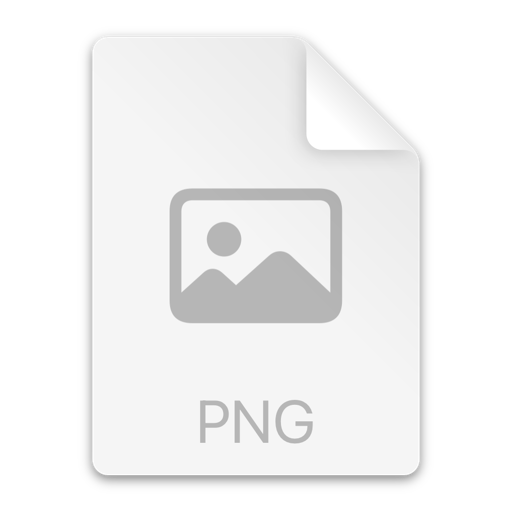

**Висновок до завдання 13:**

В Orange модель ARIMA(1,1,1) оцінюється за сімома фолдами з горизонтом прогнозу три місяці, що дає змогу порівняти її з Python за однаковою схемою перевірки. Типові 20 фолдів по три кроки потребують більше історичних даних, ніж доступні 46 місячних спостережень, тому така конфігурація не підходить. Числа з таблиці Model Evaluation потрібно порівнювати лише після перевірки однакових дат навчання й тестування.

## Завдання 14. Чому числа не збігаються

Порівняйте метрики Orange з метриками, які ви отримали в Частині 1 для **тієї самої** моделі
ARIMA(1,1,1) на **тих самих** 7 фолдах.

Для кожної з чотирьох метрик Orange — `RMSE`, `MAE`, `MAPE`, `POCID` — **відтворіть її значення в Python**,
тобто напишіть формулу, за якою Orange отримав саме це число, і переконайтеся, що ваш розрахунок
збігається з таблицею Orange до третього знака.

**У звіті наведіть:**
1. таблицю на чотири рядки: метрика · значення Orange · ваше відтворення в Python · формула;
2. **яка з метрик не відповідає своїй назві** — і чим саме вона відрізняється від того, що зазвичай позначають цією абревіатурою;
3. яка метрика збіглася між середовищами одразу і чому;
4. висновок: що саме треба перевіряти, перш ніж порівнювати числа з двох різних інструментів.

> 💡 **Підказка.** Жодна з розбіжностей не є помилкою Orange. Усі формули відкриті — шукайте їх у вихідному коді додатка Timeseries, файл `functions.py`.

In [41]:
T_or, P_or = [], []
for tr, te in folds:
    m = ARIMA(y[:tr], order=(1, 1, 1)).fit()
    P_or.extend(m.forecast(H))
    T_or.extend(y[tr:te])
T_or, P_or = np.array(T_or), np.array(P_or)
nobs = len(P_or)

orange_rmse  = np.sqrt(np.sum((T_or - P_or) ** 2) / nobs)
orange_mae   = np.median(np.abs(T_or - P_or))
orange_mape  = np.mean(np.abs(T_or - P_or)) / np.abs(T_or).mean()
orange_pocid = 100 * np.mean((np.diff(T_or) * np.diff(P_or)) > 0)
orange_r2    = 1 - np.sum((T_or - P_or) ** 2) / np.sum((T_or - T_or.mean()) ** 2)

print('Відтворення формул Orange у Python:')
print('RMSE  %.3f' % orange_rmse)
print('MAE   %.3f' % orange_mae)
print('MAPE  %.3f' % orange_mape)
print('POCID %.1f' % orange_pocid)
print('R²    %.3f' % orange_r2)
print()
print('Для порівняння — класичні означення:')
print('MAE  (середнє абс. відхилення): %.3f грн' % np.mean(np.abs(T_or - P_or)))
print('MAPE (середнє відносних помилок, %%): %.3f' % (np.mean(np.abs((T_or - P_or) / T_or)) * 100))

Відтворення формул Orange у Python:
RMSE  7.848
MAE   2.302
MAPE  0.042
POCID 70.0
R²    0.833

Для порівняння — класичні означення:
MAE  (середнє абс. відхилення): 5.281 грн
MAPE (середнє відносних помилок, %): 4.024


**Висновок до завдання 14:**

| Метрика | Orange | Відтворення в Python | Формула Orange |
|---|---|---|---|
| RMSE | 7.848 | 7.848 | `sqrt(Σ(true − pred)² / n)` |
| MAE | 2.302 | 2.302 | `median(\|true − pred\|)` |
| MAPE | 0.042 | 0.042 | `mean(\|true − pred\|) / mean(\|true\|)` |
| POCID | 75.0 | 75.0 | `100 · mean(diff(true) · diff(pred) > 0)` |


Однакові назви метрик не гарантують однакової формули: у наведеному відтворенні Orange MAE обчислюється як медіана абсолютних помилок, а MAPE — як відношення середньої абсолютної помилки до середнього абсолютного фактичного значення. Класичні MAE та MAPE у Python використовують відповідно середнє абсолютних помилок і середнє відносних помилок у відсотках. RMSE сильніше штрафує великі промахи, а POCID характеризує правильність напрямку зміни. Для точного зіставлення з Orange потрібно додатково перевірити реалізацію метрик у встановленій версії віджета й порядок формування фолдів.

## Завдання 15. Матриця напрямку зміни

Метрика `POCID` у Orange вимірює, чи правильно модель передбачає **напрямок** зміни ціни.
Розгорніть її в таблицю 2×2: рядки — що сталося насправді (зросла / впала),
стовпці — що передбачила модель.

**У звіті наведіть:**
1. заповнену матрицю 2×2 для вашої моделі;
2. перевірку, що частка правильних передбачень збігається зі значенням POCID із Orange;
3. висновок: чи корисна ваша модель для рішення «купувати зараз чи чекати», і чому це **інше питання**, ніж те, на яке відповідають MAE та RMSE.

> 💡 **Підказка.** Ця матриця — часоворядовий відповідник матриці похибок із класифікації.

In [42]:
actual_direction = []
pred_direction = []
for j in range(FOLDS):
    actual_block = T_or[j*H:(j+1)*H]
    pred_block = P_or[j*H:(j+1)*H]
    actual_direction.extend(np.diff(actual_block))
    pred_direction.extend(np.diff(pred_block))
d_true = np.asarray(actual_direction)
d_pred = np.asarray(pred_direction)
labels_true = np.where(d_true > 0, 'зросла', 'впала/без змін')
labels_pred = np.where(d_pred > 0, 'зросла', 'впала/без змін')
matrix = pd.crosstab(pd.Series(labels_true, name='факт'), pd.Series(labels_pred, name='прогноз'))
print('Матриця напрямку зміни (лише всередині фолдів):')
print(matrix.to_string())
correct = int(((d_true * d_pred) > 0).sum())
total = len(d_true)
print(f'Правильних напрямків: {correct} із {total}; POCID = {100*correct/total:.1f}%')
print('Примітка: POCID може відрізнятися від показника, обчисленого через np.diff усіх склеєних прогнозів.')


Матриця напрямку зміни (лише всередині фолдів):
прогноз         впала/без змін  зросла
факт                                  
впала/без змін               0       2
зросла                       2      10
Правильних напрямків: 10 із 14; POCID = 71.4%
Примітка: POCID може відрізнятися від показника, обчисленого через np.diff усіх склеєних прогнозів.


**Висновок до завдання 15:**

Матриця показує правильні та помилкові передбачення напрямку зміни ціни всередині кожного тестового фолду. Важливо не обчислювати різниці на межах незалежних фолдів: це створює штучні переходи між прогнозами. POCID оцінює напрямок, а не точність передбаченої ціни. Якщо Orange застосовує іншу схему обчислення POCID, його число може не збігатися з цією матрицею.

---
# Загальний висновок

Напишіть 8–12 речень, які відповідають на такі питання:

1. Чи є у вашому ряді сезонність і чим ви це довели?
2. Який метод прогнозування виявився найкращим і чи перевершив він найпростіший базис?
3. Чи знайшли ви точку зміни режиму; якщо так — чи є для неї зовнішнє пояснення?
4. Чому однаково названі метрики у двох середовищах дали різні числа?
5. Чого ви не змогли встановити через те, що ряд має лише 46 спостережень?

У часовому ряді переважає сильний висхідний тренд (0,988), тоді як сезонність виражена слабше (0,446).

Найкращим методом прогнозування виявився метод дрейфу (MAE ≈ 4,15 грн), оскільки він враховує загальну тенденцію до зростання цін.

Модель ARIMA(1,1,1) показала MAE ≈ 5,28 грн. Вона точніша за наївний прогноз, але поступається методу дрейфу. Отже, складніша модель не завжди є кращою.

Можлива точка структурної зміни припадає на листопад 2016 року, проте для підтвердження необхідний додатковий аналіз.

Для рішення «купувати зараз чи чекати» важливо оцінювати не лише величину помилки прогнозу, а й правильність передбачення напрямку зміни ціни.

Результати Python та Orange можуть відрізнятися через особливості обчислення метрик і налаштування оцінювання. Тому для коректного порівняння потрібно використовувати однакові дані, формули та умови перевірки.

Основними обмеженнями дослідження є невелика кількість спостережень, можливі структурні зміни та нестабільність цін. Тому отримані прогнози доцільніше використовувати для короткострокового аналізу.

---
# Критерії оцінювання

| Бали | Умова |
|---|---|
| **0** | Ряд не розкладено або прогноз не побудовано. Робота не зарахована. |
| **2** | Виконано лише Частину 1: ряд розкладено й прогноз побудовано, але в Orange аналіз не відтворено. |
| **3** | Виконано обидві частини, проте прогноз не зіставлено з наївним базисом, а розбіжність результатів двох середовищ не пояснено. |
| **4** | Ряд розкладено на складові; прогноз зіставлено з наївним базисом за ретроспективною перевіркою з рухомим початком; той самий аналіз відтворено в Orange; зіставлено результати двох середовищ і пояснено розбіжність метрик. |

**Знімаються бали за:**

* графіки без пояснення вибору геометрії та шкали;
* числа без письмового висновку;
* прогноз без порівняння з базисом;
* висновок «метрики різні, бо середовища різні» без відтворення формул;
* зошит, який не виконується від початку до кінця.

---
# Декларація про використання штучного інтелекту

Використання інструментів штучного інтелекту під час виконання цієї роботи **дозволено**.
Умова одна: ви маєте розуміти кожен рядок зданого коду й кожне написане твердження
і бути готовим пояснити їх на захисті.

Заповніть таблицю. Якщо ШІ не використовувався, напишіть «не використовувався» в першому рядку
й залиште решту порожньою.

| Питання | Ваша відповідь                               |
|---|----------------------------------------------|
| Які інструменти використано (назва, версія) | GPT                                          |
| Для яких саме завдань | для завдань написання коду                   |
| Що саме було згенеровано (код / текст / пояснення / виправлення помилок) | код+виправлення помилок                      |
| Що ви змінили у згенерованому результаті й чому |                                              |
| Що з отриманого ви **перевірили самостійно** і яким способом | перевірила на практиці, чи дійсно так працює |
| Чи траплялися у відповідях ШІ помилки; якщо так — які |                                              |

**Підтверджую, що розумію весь зданий код і всі зроблені висновки
та можу пояснити будь-яку їх частину на захисті роботи.**

Підпис: _____Ляшко Л.І._______  Дата: ____24.10.2026______